# Tutorial: 10x Multiome PBMC

This tutorial runs the complete pycisTopic workflow on the scATAC-seq part of the
[10k human PBMC Multiome dataset](https://www.10xgenomics.com/datasets/10-k-human-pbm-cs-multiome-v-1-0-chromium-controller-1-standard-2-0-0)
from 10x Genomics:

1. cell type labels from the scRNA-seq part (with scanpy),
2. reference data: TSS annotation and chromosome sizes,
3. pseudobulk profiles per cell type, peak calling with MACS3 and consensus peaks,
4. QC and cell selection,
5. count matrix,
6. topic modeling and model selection,
7. clustering and visualization with scanpy,
8. topic QC, annotation and binarization,
9. differentially accessible regions (DARs),
10. signature enrichment,
11. gene activity.

Most steps are run with the `pycistopic` command line tool (as you would do on a
compute cluster); results are inspected in Python. Every step is also available as a
Python function (see [Workflow](../features.rst)).

```{note}
The whole tutorial takes about 1.5 hours with 20 threads and needs about 30 GB of
memory. Topic modeling (about 35 minutes for 8 models) is the longest step.
```

Requirements: pycisTopic (see [Installation](../installation.rst)) and scanpy with
leidenalg for the scRNA-seq analysis and plots:

```bash
pip install scanpy leidenalg
```

In [1]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import scanpy as sc
from IPython.display import Image, display

# Number of threads to use.
N_CPU = 20

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(5, 5))

/tmp/ipykernel_2050573/804404411.py:15: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(5, 5))


## Download the data

We use the ATAC fragments file (with its index) and the filtered gene expression
matrix.

In [2]:
%%bash
mkdir -p data
url=https://cf.10xgenomics.com/samples/cell-arc/2.0.0/10k_PBMC_Multiome_nextgem_Chromium_Controller/10k_PBMC_Multiome_nextgem_Chromium_Controller
for file in atac_fragments.tsv.gz atac_fragments.tsv.gz.tbi filtered_feature_bc_matrix.h5; do
    if [ ! -e "data/pbmc_10k_${file}" ]; then
        wget -q -O "data/pbmc_10k_${file}" "${url}_${file}"
    fi
done
ls -lh data

total 3.5G
-rw-r--r-- 2 user group 3.3G Oct 16 22:41 pbmc_10k_atac_fragments.tsv.gz
-rw-r

--r-- 2 user group 1.5M Oct 16 22:41 pbmc_10k_atac_fragments.tsv.gz.tbi
-rw-r--r-- 2 u013

8640 domain users 159M Oct 16 22:41 pbmc_10k_filtered_feature_bc_matrix.h5


## Cell type labels from scRNA-seq

Pseudobulk profiles per cell type are used to call peaks, so we first get cell type
labels from the gene expression part of the Multiome data with a standard scanpy
analysis.

In [3]:
rna = sc.read_10x_h5("data/pbmc_10k_filtered_feature_bc_matrix.h5")
rna.var_names_make_unique()
rna.var["mt"] = rna.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(rna, qc_vars=["mt"], inplace=True, percent_top=None, log1p=False)
rna = rna[(rna.obs["n_genes_by_counts"] > 300) & (rna.obs["pct_counts_mt"] < 20)].copy()
sc.pp.filter_genes(rna, min_cells=3)

sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=2000)
sc.pp.pca(rna, n_comps=50, mask_var="highly_variable")
sc.pp.neighbors(rna, n_neighbors=15, n_pcs=30)
sc.tl.leiden(rna, resolution=0.8, flavor="igraph", n_iterations=2, random_state=0)
sc.tl.umap(rna, random_state=0)
rna

.../site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 10004 × 25638
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)

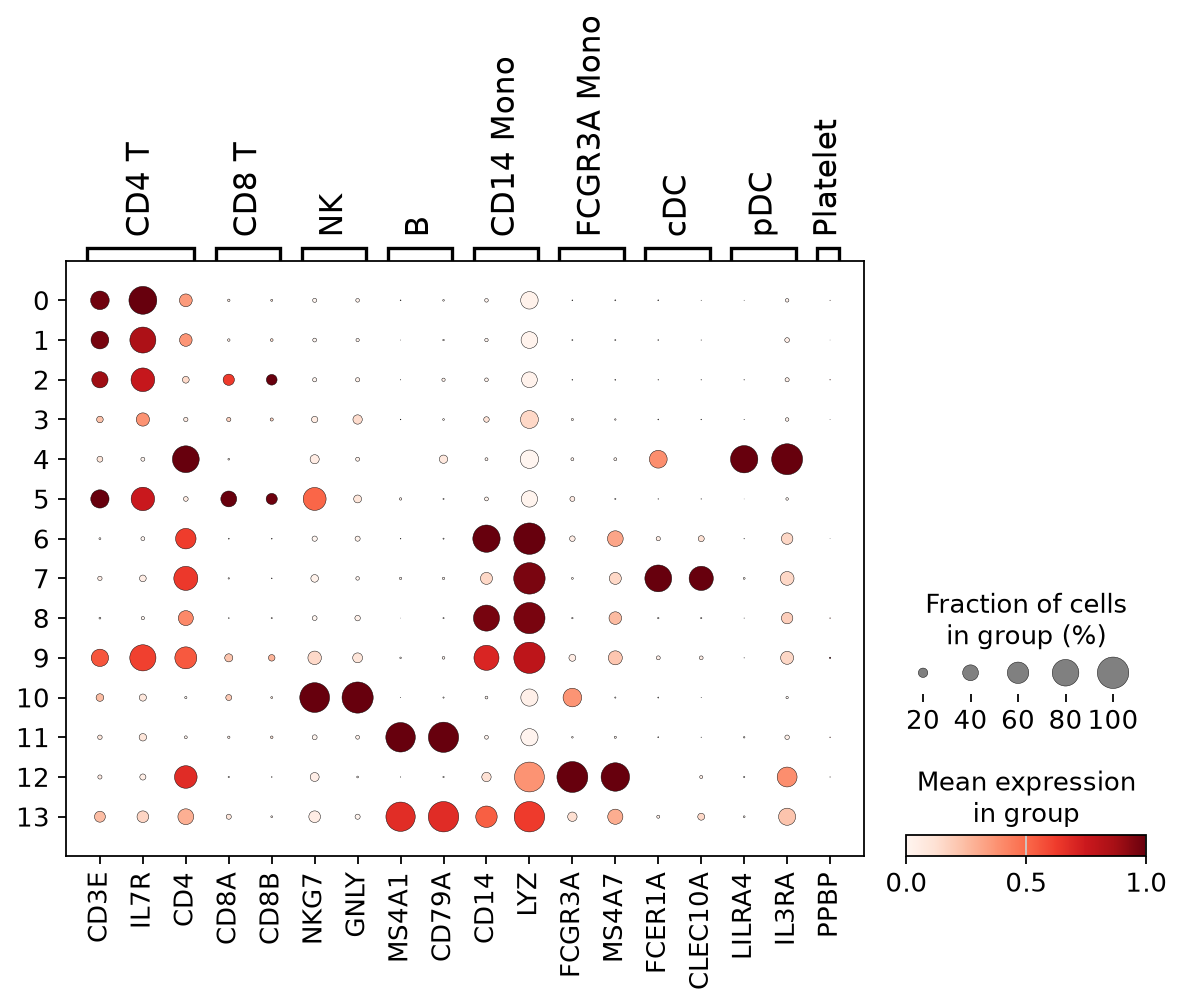

In [4]:
markers = {
    "CD4 T": ["CD3E", "IL7R", "CD4"],
    "CD8 T": ["CD8A", "CD8B"],
    "NK": ["NKG7", "GNLY"],
    "B": ["MS4A1", "CD79A"],
    "CD14 Mono": ["CD14", "LYZ"],
    "FCGR3A Mono": ["FCGR3A", "MS4A7"],
    "cDC": ["FCER1A", "CLEC10A"],
    "pDC": ["LILRA4", "IL3RA"],
    "Platelet": ["PPBP"],
}
sc.pl.dotplot(rna, markers, groupby="leiden", standard_scale="var")

Based on the marker genes, we annotate the clusters. Cluster 3 has no clear markers
(low quality cells) and clusters 9 and 13 express markers of multiple cell types
(doublets); these cells are not used to call peaks.

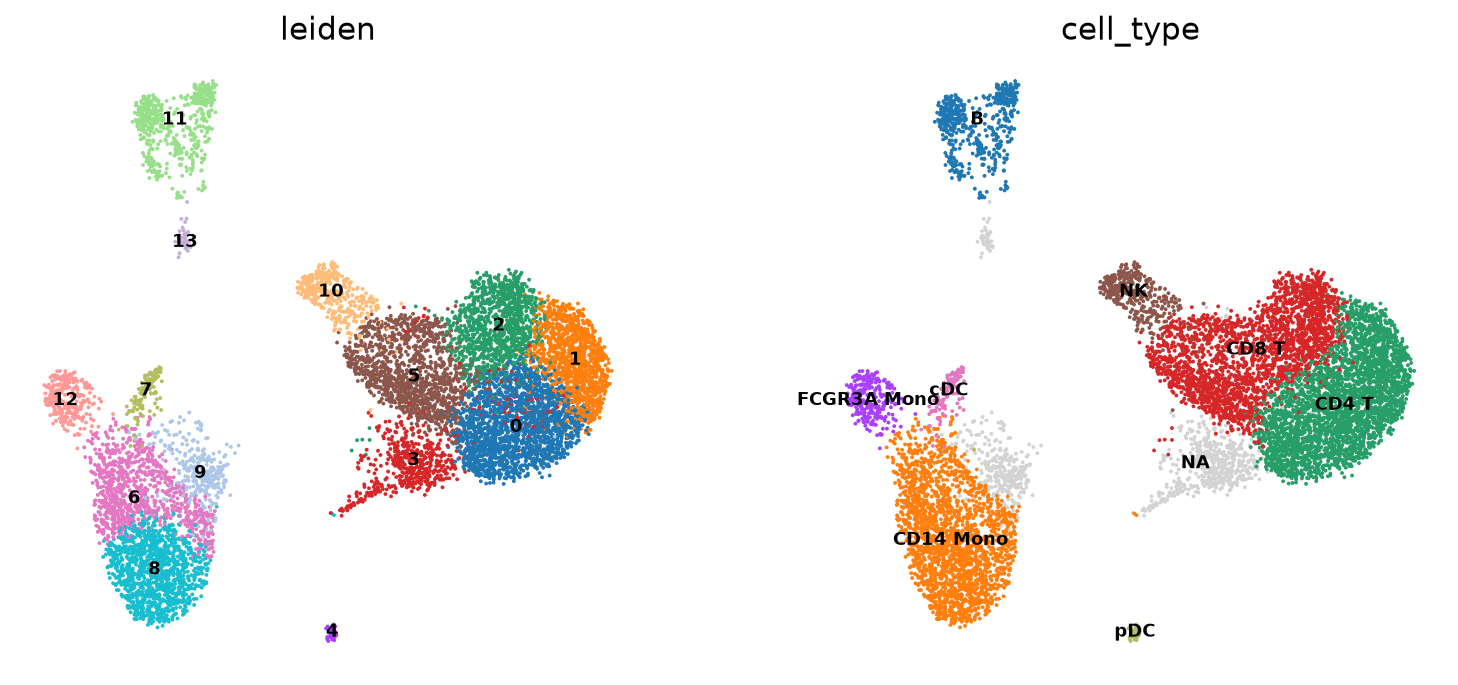

cell_type
CD4 T          3163
CD8 T          2431
CD14 Mono      2061
B               560
NK              376
FCGR3A Mono     267
cDC             126
pDC              47
Name: count, dtype: int64

In [5]:
cluster_to_cell_type = {
    "0": "CD4 T", "1": "CD4 T", "2": "CD8 T", "5": "CD8 T", "10": "NK", "11": "B",
    "6": "CD14 Mono", "8": "CD14 Mono", "12": "FCGR3A Mono", "7": "cDC", "4": "pDC",
}  # fmt: skip
rna.obs["cell_type"] = rna.obs["leiden"].map(cluster_to_cell_type).astype("category")
sc.pl.umap(rna, color=["leiden", "cell_type"], legend_loc="on data", legend_fontsize=8)
rna.obs["cell_type"].value_counts()

pycisTopic names cell barcodes `BARCODE___SAMPLE` (the `-1` suffix of 10x barcodes is
removed). We write the cell type labels to a TSV file with barcodes in this format.

In [6]:
cell_data = rna.obs.loc[rna.obs["cell_type"].notna(), ["cell_type"]].copy()
cell_data.index = cell_data.index.str.removesuffix("-1") + "___pbmc_10k"
cell_data.index.name = "cell_barcode"
cell_data.to_csv("cell_data.tsv", sep="\t")
cell_data.head()

,cell_type
cell_barcode,
AAACAGCCAACAACAA___pbmc_10k,CD4 T
AAACAGCCAAGGACCA___pbmc_10k,CD4 T
AAACAGCCACAATGCC___pbmc_10k,CD8 T
AAACAGCCATGAGCAG___pbmc_10k,CD8 T
AAACATGCAAGATTCT___pbmc_10k,CD4 T


## Reference data

pycisTopic needs a TSS annotation (for QC and gene activity) and chromosome sizes. The
TSS annotation is downloaded from Ensembl BioMart and the chromosome names are
converted from Ensembl (`1`) to UCSC (`chr1`) names, as used by Cell Ranger ARC, with a
chromosome alias mapping from UCSC.

In [7]:
!mkdir -p ref
!pycistopic tss get_ucsc_chrom_sizes_and_alias_mapping --ucsc hg38 --chrom-sizes-alias ref/hg38.chrom_sizes_and_alias.tsv
!pycistopic tss get_tss -n hsapiens_gene_ensembl -o ref/hg38.tss.bed --to-chrom-source ucsc --chrom-sizes-alias ref/hg38.chrom_sizes_and_alias.tsv
!head -n 3 ref/hg38.tss.bed

- Get TSS annotation from Ensembl BioMart with the following settings:
  - biomart_name: "hsapiens_gene_ensembl"
  - biomart_host: "http://www.ensembl.org"
  - transcript_type: ['protein_coding']
  - use_cache: True


- Loading chromosome sizes and alias mapping from "ref/hg38.chrom_sizes_and_alias.tsv".
- Update chromosome names in TSS annotation to "ucsc" chromosome names.
- Writing TSS annotation BED file to "ref/hg38.tss.bed".


# Chromosome	Gene_start	Gene_end	Gene	Score	Strand	TSS_start	TSS_end	Transcript_type	Ensembl_gene_id
chrM	3306	4262	MT-ND1	.	+	3306	3307	protein_coding	ENSG00000198888
chrM	4469	5511	MT-ND2	.	+	4469	4470	protein_coding	ENSG00000198763


We only use the primary chromosomes (`chr1`-`chr22`, `chrX` and `chrY`).

In [8]:
chrom_sizes = (
    pl.read_csv("ref/hg38.chrom_sizes_and_alias.tsv", separator="\t")
    .select(pl.col("# ucsc").alias("chrom"), pl.col("length"))
    .filter(pl.col("chrom").is_in([f"chr{c}" for c in [*range(1, 23), "X", "Y"]]))
)
chrom_sizes.write_csv("ref/hg38.chrom.sizes", separator="\t", include_header=False)
chrom_sizes.height

24

We also download the ENCODE blacklist of problematic regions, which are removed from
the consensus peaks.

In [9]:
!wget -q -O - https://raw.githubusercontent.com/Boyle-Lab/Blacklist/master/lists/hg38-blacklist.v2.bed.gz | gunzip > ref/hg38-blacklist.v2.bed
!wc -l ref/hg38-blacklist.v2.bed

636 ref/hg38-blacklist.v2.bed


## Consensus peaks

We create pseudobulk fragment files per cell type, call peaks on each of them with
MACS3 and merge them into consensus peaks with iterative peak filtering. This keeps
peaks of rare cell types (like pDCs), which would be missed when calling peaks on all
cells together.

The file mapping sample IDs to fragment files is used by several commands.

In [10]:
pd.DataFrame(
    {"sample": ["pbmc_10k"], "fragments_filename": ["data/pbmc_10k_atac_fragments.tsv.gz"]}
).to_csv("sample_fragments.tsv", sep="\t", index=False)

# Fragment files use 10x barcodes with "-1", so add "-1" to the barcodes (-d).
!pycistopic pseudobulk --cell_data cell_data.tsv -g cell_type -f sample_fragments.tsv -c ref/hg38.chrom.sizes -o pseudobulk -d -1 -n {N_CPU}
!ls pseudobulk

[W::hts_idx_load3] The index file is older than the data file: data/pbmc_10k_atac_fragments.tsv.gz.tbi


B	pseudobulk/B.fragments.tsv.gz
CD14_Mono	pseudobulk/CD14_Mono.fragments.tsv.gz
CD4_T	pseudobulk/CD4_T.fragments.tsv.gz
CD8_T	pseudobulk/CD8_T.fragments.tsv.gz
FCGR3A_Mono	pseudobulk/FCGR3A_Mono.fragments.tsv.gz
NK	pseudobulk/NK.fragments.tsv.gz
cDC	pseudobulk/cDC.fragments.tsv.gz
pDC	pseudobulk/pDC.fragments.tsv.gz


B.fragments.tsv.gz	    CD8_T.fragments.tsv.gz	  NK.fragments.tsv.gz
CD14_Mono.fragments.tsv.gz  cDC.fragments.tsv.gz	  pDC.fragments.tsv.gz
CD4_T.fragments.tsv.gz	    FCGR3A_Mono.fragments.tsv.gz  tmp


In [11]:
!pycistopic callpeaks -i pseudobulk -o macs -g hs -n {N_CPU}
!wc -l macs/*_summits.bed

B	macs/B_summits.bed
CD14_Mono	macs/CD14_Mono_summits.bed
CD4_T	macs/CD4_T_summits.bed
CD8_T	macs/CD8_T_summits.bed
FCGR3A_Mono	macs/FCGR3A_Mono_summits.bed
NK	macs/NK_summits.bed
cDC	macs/cDC_summits.bed
pDC	macs/pDC_summits.bed


  115286 macs/B_summits.bed
  212240 macs/CD14_Mono_summits.bed
  165195 macs/CD4_T_summits.bed
  133249 macs/CD8_T_summits.bed
   72375 macs/cDC_summits.bed
   99445 macs/FCGR3A_Mono_summits.bed
   94285 macs/NK_summits.bed
   59230 macs/pDC_summits.bed
  951305 total


For each cell type, summits are extended to 500 bp peaks and overlapping peaks are
filtered iteratively (the most significant peak is kept). The peaks of all cell types
are then filtered in the same way, after normalizing the significance per cell type.

In [12]:
!pycistopic consensus_peaks -i macs -c ref/hg38.chrom.sizes -b ref/hg38-blacklist.v2.bed -o consensus_peaks.bed
!head -n 3 consensus_peaks.bed
!wc -l consensus_peaks.bed

Reading peaks for "B" from "macs/B_summits.bed".
Reading peaks for "CD14_Mono" from "macs/CD14_Mono_summits.bed".


Reading peaks for "CD4_T" from "macs/CD4_T_summits.bed".
Reading peaks for "CD8_T" from "macs/CD8_T_summits.bed".


Reading peaks for "FCGR3A_Mono" from "macs/FCGR3A_Mono_summits.bed".
Reading peaks for "NK" from "macs/NK_summits.bed".


Reading peaks for "cDC" from "macs/cDC_summits.bed".


Reading peaks for "pDC" from "macs/pDC_summits.bed".


Writing 352382 consensus peaks to "consensus_peaks.bed".


chr1	817093	817593	cDC_peak_2	27.4312
chr1	818838	819338	CD14_Mono_peak_7	0.168318
chr1	819770	820270	FCGR3A_Mono_peak_6	1.04218


352382 consensus_peaks.bed


## QC and cell selection

`pycistopic qc run` computes QC statistics per sample (barcode rank, insert size
distribution and TSS profile) and per cell barcode (number of fragments in peaks,
fraction of fragments in peaks, TSS enrichment and duplication ratio).

In [13]:
!pycistopic qc run -f data/pbmc_10k_atac_fragments.tsv.gz -r consensus_peaks.bed -t ref/hg38.tss.bed -o qc/pbmc_10k --threads {N_CPU}
!ls qc

pbmc_10k.cbs_for_otsu_thresholds.tsv
pbmc_10k.fragments_insert_size_dist.parquet
pbmc_10k.fragments_stats_per_cb_for_otsu_thresholds.parquet
pbmc_10k.fragments_stats_per_cb_for_otsu_thresholds.tsv
pbmc_10k.fragments_stats_per_cb.parquet
pbmc_10k.otsu_thresholds.tsv
pbmc_10k.pycistopic_qc.log
pbmc_10k.tss_norm_matrix_sample.parquet


pbmc_10k:
	Using automatic threshold for unique fragments: 1293.502514205343
	Using automatic threshold for TSS enrichment: 13.297116960627111


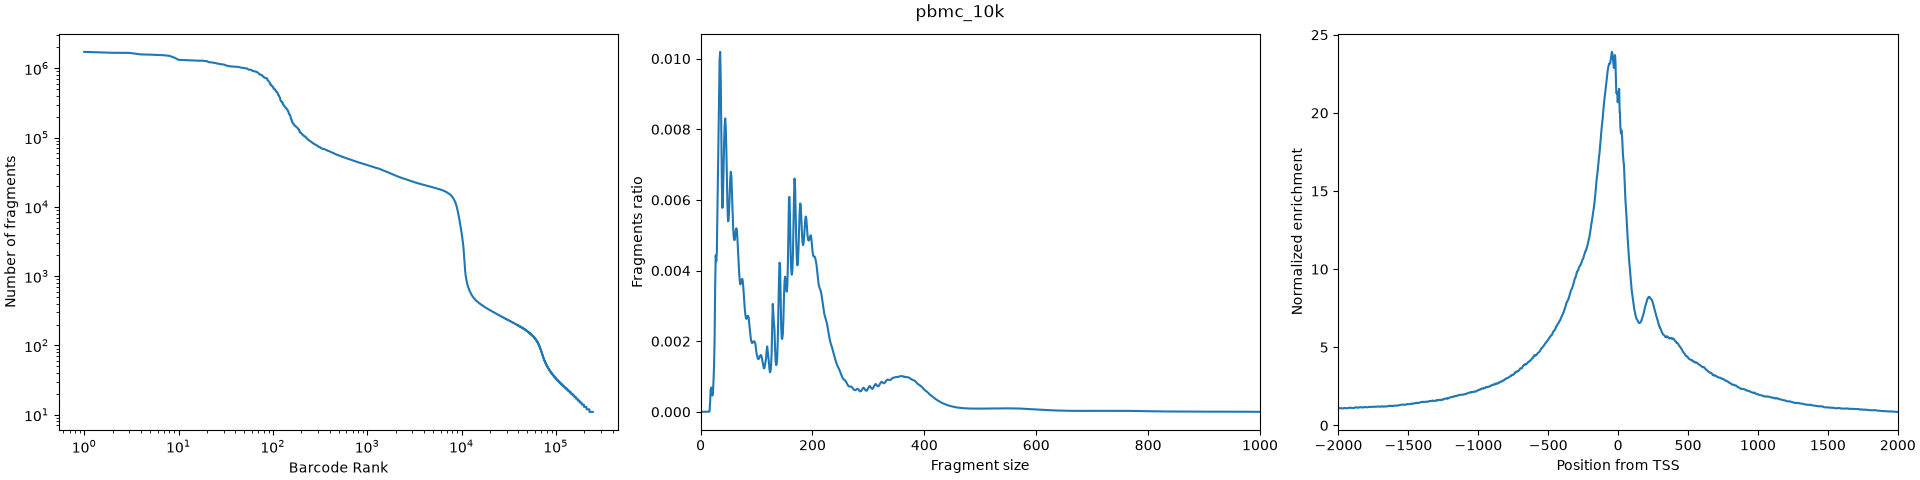

In [14]:
!pycistopic qc plot -s pbmc_10k -o qc
display(Image("qc/pbmc_10k_sample_stats.png"))

In a good sample, the barcode rank plot shows a steep drop-off between cells and empty
droplets, the insert size distribution shows a nucleosome free peak and
mono-nucleosome peak, and fragments are enriched at the TSS.

Cell barcodes are selected based on the number of unique fragments in peaks and the
TSS enrichment. Thresholds are determined automatically with Otsu's method (red lines),
but they can be set manually too.

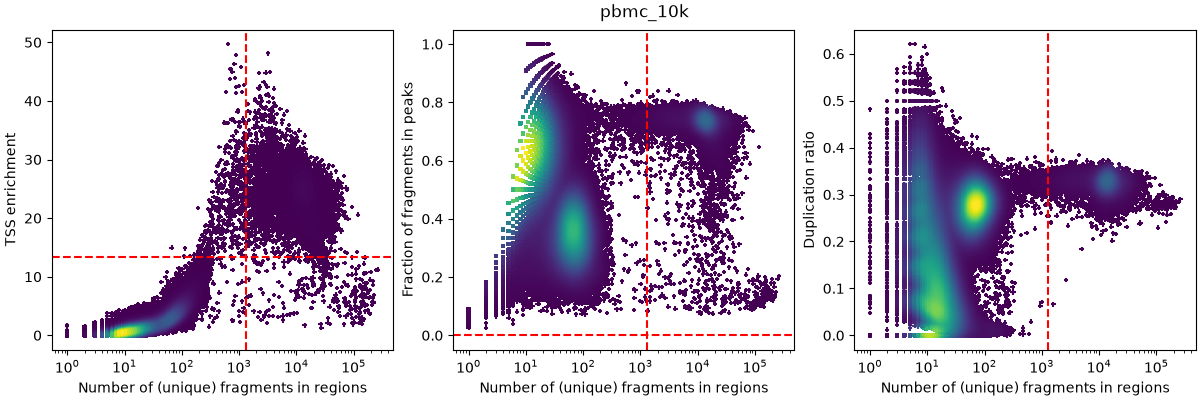

unique_fragments_in_peaks_count_otsu_threshold    1293.502514
tss_enrichment_otsu_threshold                       13.297117
Name: 0, dtype: float64

In [15]:
display(Image("qc/pbmc_10k_bc_stats.png"))
otsu_thresholds = pd.read_csv("qc/pbmc_10k.otsu_thresholds.tsv", sep="\t").iloc[0]
otsu_thresholds

In [16]:
fragments_threshold = otsu_thresholds["unique_fragments_in_peaks_count_otsu_threshold"]
tss_threshold = otsu_thresholds["tss_enrichment_otsu_threshold"]
!pycistopic qc filter -s pbmc_10k -o qc -f {fragments_threshold} -t {tss_threshold}
cell_barcodes_file = f"qc/pbmc_10k.min_fragments_{fragments_threshold}_min_tss_{tss_threshold}_min_frip_0.0.cbs.txt"
!wc -l {cell_barcodes_file}

Writing selected cell barcodes for "pbmc_10k" based on QC statistics with:
  - minimum unique fragments:	1293.502514205343
  - minimum TSS threshold:	13.297116960627111
  - minimum FRiP threshold:	0.0
to "qc/pbmc_10k.min_fragments_1293.502514205343_min_tss_13.297116960627111_min_frip_0.0.cbs.txt".


10350 qc/pbmc_10k.min_fragments_1293.502514205343_min_tss_13.297116960627111_min_frip_0.0.cbs.txt


## Count matrix

The binary count matrix (regions x cells) of the selected cells is created from the
fragment files of all samples (here only one).

In [17]:
pd.DataFrame(
    {"sample": ["pbmc_10k"], "cell_barcodes_filename": [cell_barcodes_file]}
).to_csv("sample_barcodes.tsv", sep="\t", index=False)

!pycistopic count_matrix create -f sample_fragments.tsv -c sample_barcodes.tsv -r consensus_peaks.bed -o matrix/pbmc_10k -d -1
!ls -lh matrix

Fragment matrix will be generated for following samples: 
	pbmc_10k
Reading fragments files and creating fragment matrix ...
	pbmc_10k	data/pbmc_10k_atac_fragments.tsv.gz


Generated fragment matrix with shape: (352382, 10350)
Merging fragment matrix...


Writing:
  - fragment matrix: "matrix/pbmc_10k.matrix.mtx"


  - cell names: "matrix/pbmc_10k.cell_barcodes.tsv"
  - region names: "matrix/pbmc_10k.region_ids.tsv"


total 1.5G
-rw-r--r-- 1 user group 284K Oct 17 15:09 pbmc_10k.cell_barcodes.tsv
-rw-r--r-- 1 user group 1.5G Oct 17 15:09 pbmc_10k.matrix.mtx
-rw-r--r-- 1 user group 8.1M Oct 17 15:09 pbmc_10k.region_ids.tsv


## Topic modeling

Topic models are trained with latent Dirichlet allocation (LDA) and collapsed Gibbs
sampling. The number of topics is not known beforehand, so we train models with
different numbers of topics and compare them.

```{tip}
`pycistopic topic_modeling mallet` trains the same models with Mallet (which needs
Java) instead of the built-in parallel sampler; the other topic modeling subcommands
work for both.
```

In [18]:
!pycistopic topic_modeling lda run -i matrix/pbmc_10k.matrix.mtx -o models/pbmc_10k -t 5 10 15 20 25 30 40 50 -p {N_CPU} -n 500 -s 555 -v 2>&1 | grep -E "Trained|Created"

2026-10-17 15:10:07,053 pycisTopic.topic_modeling.lda INFO     Created corpus with 116234469 tokens (10350 cells, 352382 regions) in 9s.


2026-10-17 15:11:41,677 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 5 topics in 95s.


2026-10-17 15:13:39,566 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 10 topics in 118s.


2026-10-17 15:16:07,874 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 15 topics in 148s.


2026-10-17 15:18:53,890 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 20 topics in 166s.


2026-10-17 15:22:06,036 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 25 topics in 192s.


2026-10-17 15:25:39,692 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 30 topics in 213s.


2026-10-17 15:29:40,808 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 40 topics in 241s.


2026-10-17 15:33:42,794 pycisTopic.topic_modeling.lda INFO     Trained LDA model with 50 topics in 241s.


Read binary accessibility matrix from "matrix/pbmc_10k.matrix.mtx" Matrix Market file.


Calculate model evaluation statistics for 5 topics from "models/pbmc_10k.5_topics.*"...


Calculate model evaluation statistics for 10 topics from "models/pbmc_10k.10_topics.*"...


Calculate model evaluation statistics for 15 topics from "models/pbmc_10k.15_topics.*"...


Calculate model evaluation statistics for 20 topics from "models/pbmc_10k.20_topics.*"...


Calculate model evaluation statistics for 25 topics from "models/pbmc_10k.25_topics.*"...


Calculate model evaluation statistics for 30 topics from "models/pbmc_10k.30_topics.*"...


Calculate model evaluation statistics for 40 topics from "models/pbmc_10k.40_topics.*"...


Calculate model evaluation statistics for 50 topics from "models/pbmc_10k.50_topics.*"...


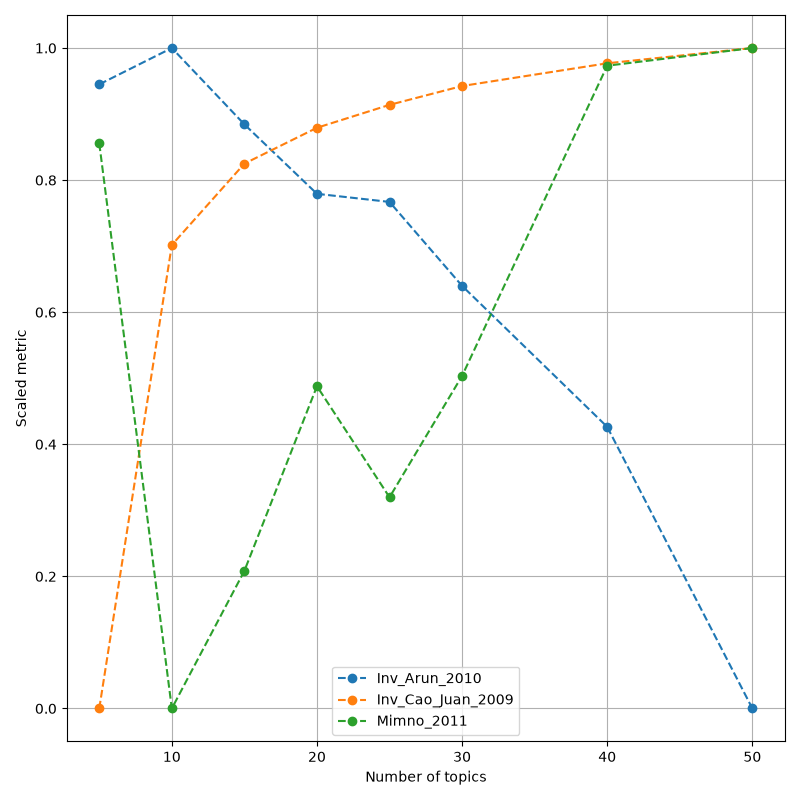

In [19]:
!pycistopic topic_modeling lda stats -i matrix/pbmc_10k.matrix.mtx -o models/pbmc_10k -t 5 10 15 20 25 30 40 50
!pycistopic topic_modeling lda plot_stats -o models/pbmc_10k -t 5 10 15 20 25 30 40 50
display(Image("models/pbmc_10k.model_evaluation_stats.png"))

The metrics are scaled between 0 and 1 and they often do not agree. The exact number
of topics is not critical: with enough topics, each cell type and its regulatory
programs are captured by separate topics. Here we use 30 topics, which separate all
cell types, including rare pDCs and cDCs (see below).

In [20]:
N_TOPICS = 30
!pycistopic topic_modeling lda create_anndata -i matrix/pbmc_10k.matrix.mtx -o models/pbmc_10k -t {N_TOPICS} --qc_dir qc -d -1

Reading Mallet results ...


Created AnnData object with shape: (10350, 352382)


Adding QC statistics from "qc" for samples: ['pbmc_10k']


Writing to: models/pbmc_10k.30_topics.h5ad


## Clustering and visualization

The AnnData file contains the cell-topic probabilities (`.obsm["X_topic"]`), the
region-topic probabilities (`.varm["topic"]`), the QC statistics of the cells
(`.obs`) and the model parameters and statistics (`.uns["pycistopic"]`). It can be
used directly with scanpy.

In [21]:
adata = ad.read_h5ad(f"models/pbmc_10k.{N_TOPICS}_topics.h5ad")

# Add RNA cell type labels (cells without a label passed ATAC QC, but not RNA QC or
# were low quality cells or doublets in the RNA analysis).
cell_types = pd.read_csv("cell_data.tsv", sep="\t", index_col=0)["cell_type"]
adata.obs["cell_type"] = pd.Categorical(cell_types.reindex(adata.obs_names))
adata

AnnData object with n_obs × n_vars = 10350 × 352382
    obs: 'barcode_rank', 'total_fragments_count', 'log10_total_fragments_count', 'unique_fragments_count', 'log10_unique_fragments_count', 'total_fragments_in_peaks_count', 'log10_total_fragments_in_peaks_count', 'unique_fragments_in_peaks_count', 'log10_unique_fragments_in_peaks_count', 'fraction_of_fragments_in_peaks', 'duplication_count', 'duplication_ratio', 'nucleosome_signal', 'tss_enrichment', 'pdf_values_for_tss_enrichment', 'pdf_values_for_fraction_of_fragments_in_peaks', 'pdf_values_for_duplication_ratio', 'sample_id', 'cell_type'
    var: 'Chromosome', 'Start', 'End'
    uns: 'pycistopic'
    obsm: 'X_topic'
    varm: 'topic'

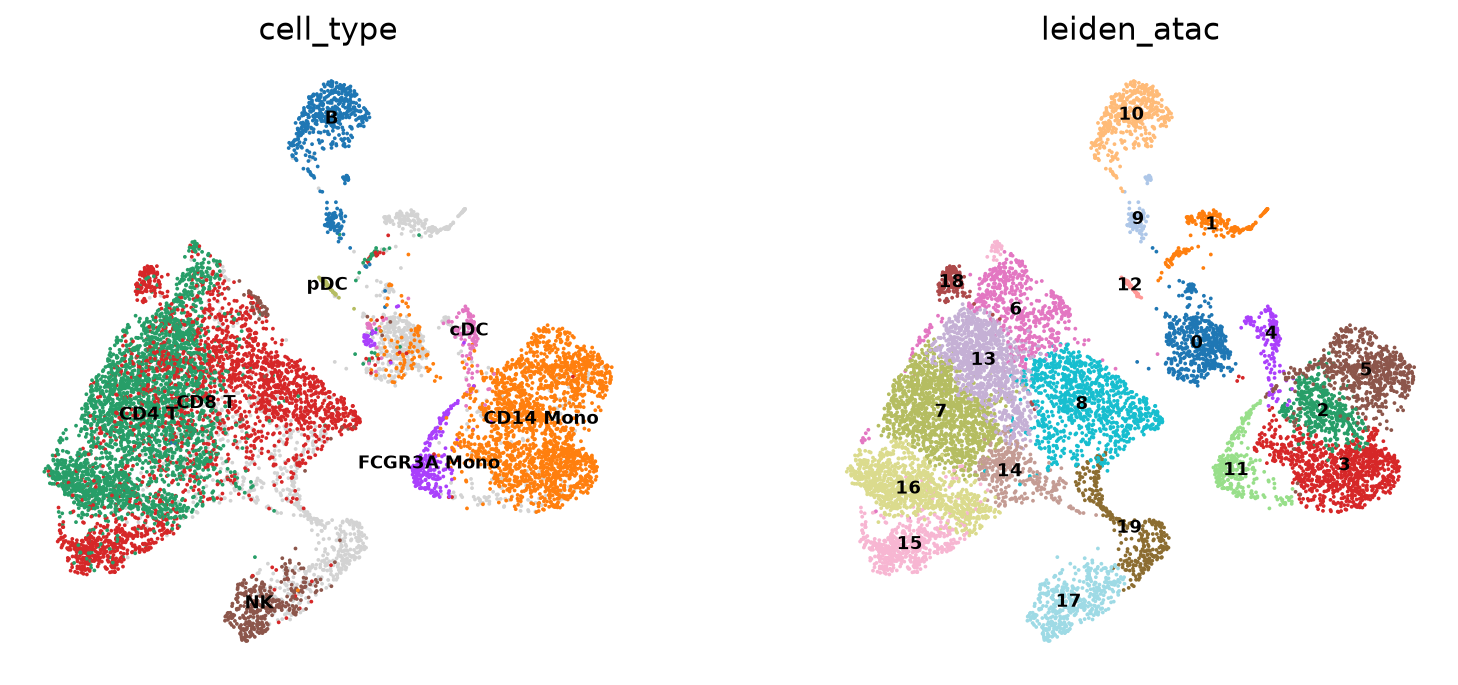

In [22]:
sc.pp.neighbors(adata, use_rep="X_topic", n_neighbors=15)
sc.tl.umap(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.6, key_added="leiden_atac", flavor="igraph", n_iterations=2, random_state=0)
sc.pl.umap(adata, color=["cell_type", "leiden_atac"], legend_loc="on data", legend_fontsize=8, na_in_legend=False)

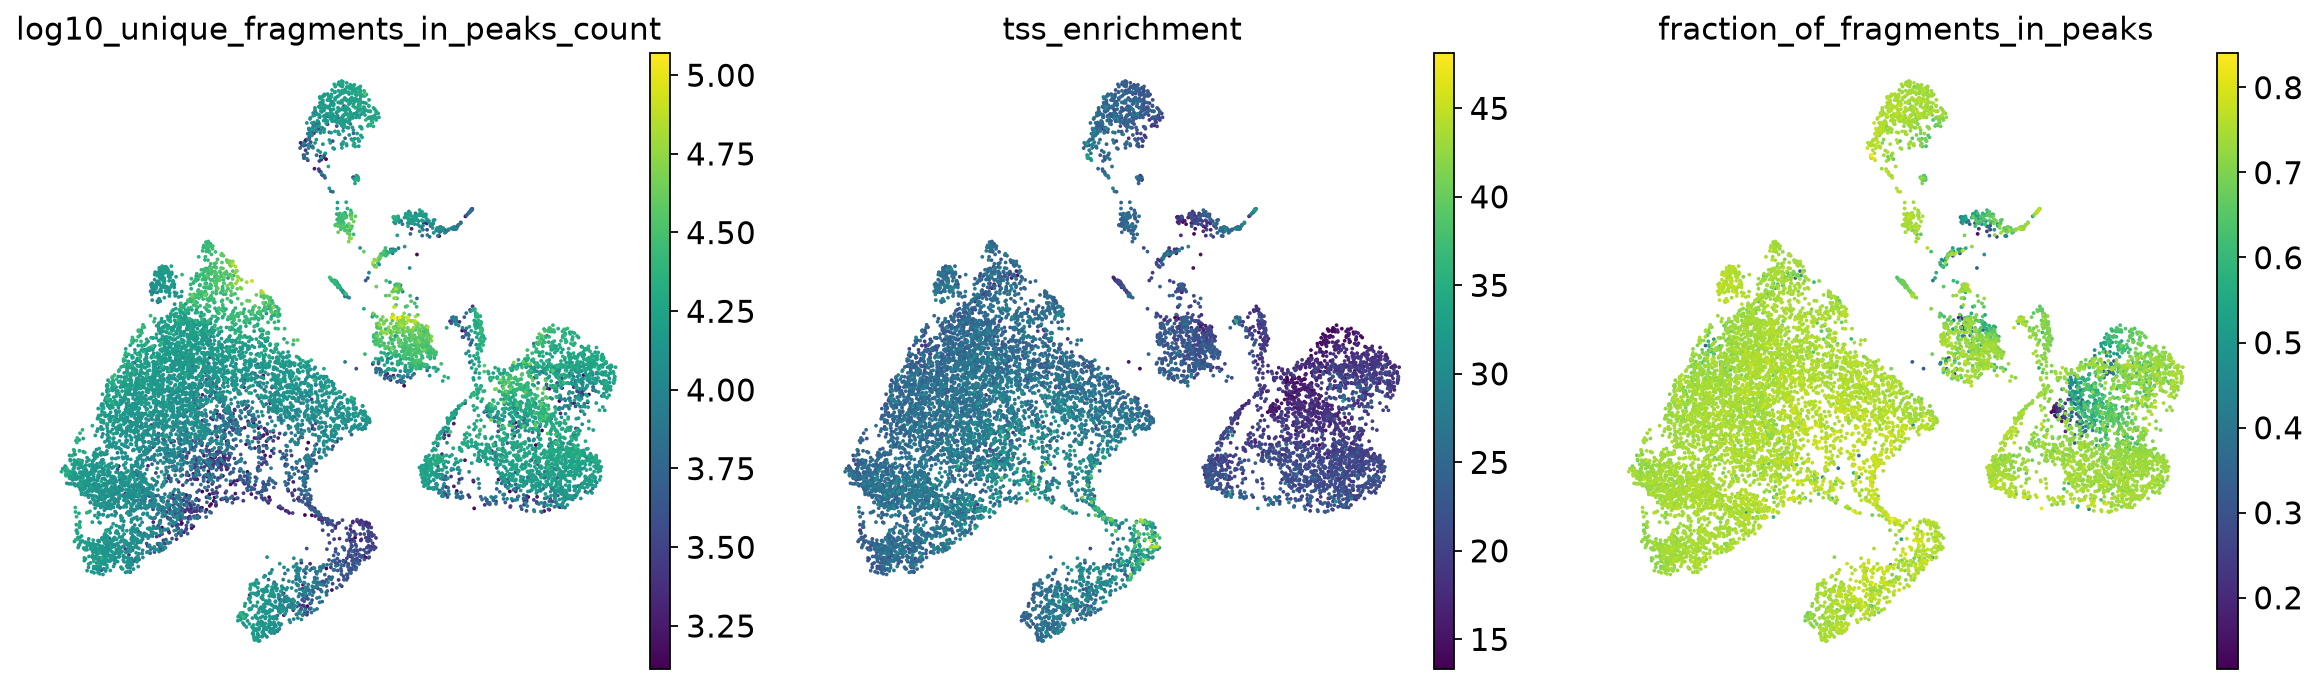

In [23]:
sc.pl.umap(
    adata,
    color=["log10_unique_fragments_in_peaks_count", "tss_enrichment", "fraction_of_fragments_in_peaks"],
    cmap="viridis",
)

Topics represent sets of co-accessible regions. Many topics are specific to a cell
type, others are shared or general.

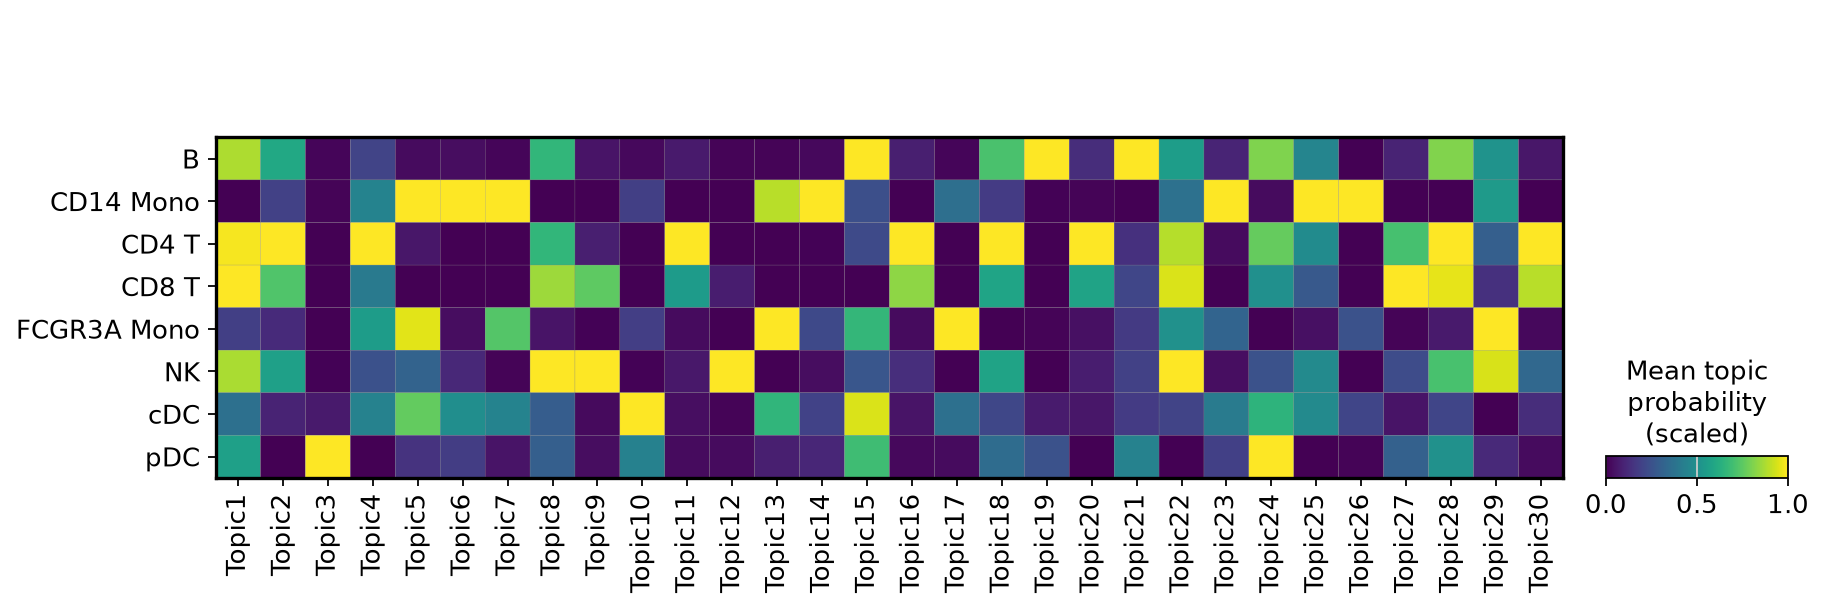

In [24]:
topic_names = [f"Topic{i + 1}" for i in range(N_TOPICS)]
topics = ad.AnnData(adata.obsm["X_topic"], obs=adata.obs[["cell_type"]])
topics.var_names = topic_names
sc.pl.matrixplot(
    topics[topics.obs["cell_type"].notna()],
    topic_names,
    groupby="cell_type",
    standard_scale="var",
    cmap="viridis",
    colorbar_title="Mean topic\nprobability\n(scaled)",
)

## Topic QC and annotation

`pycistopic topic_qc` computes topic QC metrics (e.g. coherence, number of
assignments and Gini index) and annotates topics with the cell types in which they
are enriched. General topics (enriched in most cells) are often related to
promoters or technical effects.

Computing topic QC metrics ...


Annotating topics with "cell_type" ...


Writing topic QC table to "topics.tsv".
Writing topic QC plot to "topic_qc.png".


Writing AnnData with topic QC metrics to "pbmc_10k.h5ad".


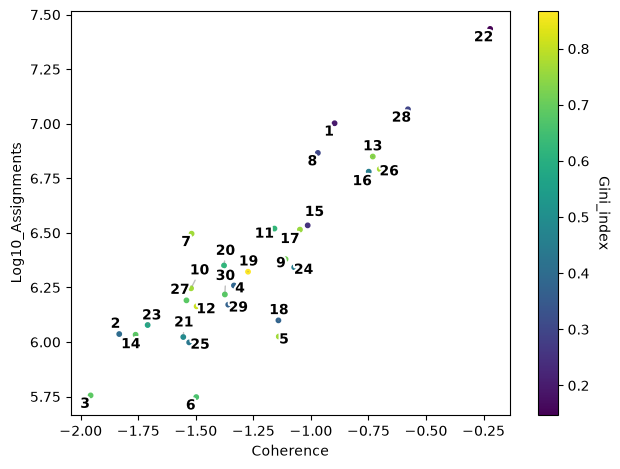

,cell_type,is_general,Coherence,Log10_Assignments,Gini_index
Topic,,,,,
Topic1,"B, CD4 T, CD8 T, NK",False,-0.90,7.00,0.20
Topic2,"CD4 T, CD8 T",False,-1.83,6.04,0.40
Topic3,pDC,False,-1.96,5.76,0.69
Topic4,"CD4 T, CD8 T",False,-1.33,6.26,0.38
Topic5,NaN,False,-1.14,6.03,0.76
Topic6,CD14 Mono,False,-1.50,5.75,0.66
Topic7,"CD14 Mono, FCGR3A Mono",False,-1.52,6.50,0.76
Topic8,"CD8 T, NK",False,-0.97,6.87,0.30
Topic9,"CD8 T, NK",False,-1.11,6.38,0.71


In [25]:
adata.write_h5ad("pbmc_10k.h5ad")
!pycistopic topic_qc -a pbmc_10k.h5ad -o pbmc_10k.h5ad --annotation cell_type --table topics.tsv --plot topic_qc.png
display(Image("topic_qc.png"))
pd.read_csv("topics.tsv", sep="\t", index_col=0)[
    ["cell_type", "is_general", "Coherence", "Log10_Assignments", "Gini_index"]
].round(2)

Topics are binarized to get the regions of each topic (`-a region`) and the cells in
which a topic is active (`-a cell`).

In [26]:
!pycistopic topic_modeling lda binarize -a region -m otsu -i pbmc_10k.h5ad -p binarized_topics
!pycistopic topic_modeling lda binarize -a cell -m aucell -i pbmc_10k.h5ad -p binarized_topics
!wc -l binarized_topics/region_Topic_*_binarized.bed | tail -n 1

Read topic model from "pbmc_10k.h5ad".


Binarizing topics ...


Saving results to "binarized_topics".


Read topic model from "pbmc_10k.h5ad".


Binarizing topics ...


Saving results to "binarized_topics".


  312884 total


## Differentially accessible regions

DARs are calculated on the imputed accessibility (cell-topic x topic-region
probabilities) of highly variable regions, with a Wilcoxon rank-sum test. By default,
each cell type is compared with all other cells (cells without a label are not used).
Other contrasts can be given in a TSV file with `--contrasts-tsv`.

In [27]:
!pycistopic dars compute_hv_regions -a pbmc_10k.h5ad --output-bed hv_regions.bed --plot hv_regions.png
!wc -l hv_regions.bed
!pycistopic dars compute_dars -a pbmc_10k.h5ad --hv-regions-bed hv_regions.bed --annotation-column cell_type --output-dir dars

Loading region-topic and cell-topic distributions...


Calculating per-region mean and dispersion on normalized imputed accessibility...
region_topic shape: (352382, 30)
cell_topic shape: (30, 10350)
2026-10-17 15:35:10,324 cisTopic     INFO     Calculate total imputed accessibility per cell.
2026-10-17 15:35:10,324 cisTopic     INFO     Allocate 0.771 GiB of RAM for calculating (partial) imputed accessibility per cell for (10350) cells for chunk of 20000 regions.
2026-10-17 15:35:10,324 cisTopic     INFO     Calculate (partial) imputed accessibility per cell for regions 0-20000 (out of 352382).
2026-10-17 15:35:10,324 cisTopic     INFO       - Calculate imputed accessibility for the current chunk of regions.


2026-10-17 15:35:10,416 cisTopic     INFO       - Scale imputed accessibility matrix chunk ("count" matrix).


2026-10-17 15:35:10,518 cisTopic     INFO       - Only keep integer part.


2026-10-17 15:35:10,614 cisTopic     INFO       - Get non-zero regions.


...

2026-10-17 15:36:49,092 cisTopic     INFO       - Scale imputed accessibility matrix chunk ("count" matrix).


2026-10-17 15:36:49,125 cisTopic     INFO       - Only keep integer part.


2026-10-17 15:36:49,155 cisTopic     INFO       - Get non-zero regions.
2026-10-17 15:36:49,157 cisTopic     INFO       - Calculate Wilcoxon test p-values.


2026-10-17 15:36:49,482 cisTopic     INFO       - Calculate log2 fold change.
2026-10-17 15:36:49,504 cisTopic     INFO     Finished calculating adjusted Wilcoxon test p-values and log2 fold change for imputed accessibility of foreground cells vs background cells for each highly variable region for "fg_pDC_vs_bg_others".


[fg_pDC_vs_bg_others] Saved 9297 DARs to dars/DARs_fg_pDC_vs_bg_others.bed

DARs computation completed. 8 newly computed, 0 skipped (already existed), 0 empty (no HV regions left after filtering), 8 total contrasts.


In [28]:
dar_files = sorted(Path("dars").glob("DARs_*.bed"))
pd.Series({f.name: sum(1 for _ in open(f)) for f in dar_files}, name="DARs")

DARs_fg_B_vs_bg_others.bed               8138
DARs_fg_CD14 Mono_vs_bg_others.bed      26089
DARs_fg_CD4 T_vs_bg_others.bed           8888
DARs_fg_CD8 T_vs_bg_others.bed           7346
DARs_fg_FCGR3A Mono_vs_bg_others.bed    22071
DARs_fg_NK_vs_bg_others.bed              6610
DARs_fg_cDC_vs_bg_others.bed            20708
DARs_fg_pDC_vs_bg_others.bed             9297
Name: DARs, dtype: int64

## Signature enrichment

Region sets (signatures) are scored in each cell with AUCell on the imputed
accessibility. As example, we score the DARs of each cell type.

In [29]:
signature_names = [f.name.removeprefix("DARs_fg_").split("_vs_")[0].replace(" ", "_") for f in dar_files]
names_arg = " ".join(signature_names)
files_arg = " ".join(f'"{f}"' for f in dar_files)
!pycistopic signature_enrichment -a pbmc_10k.h5ad -n {names_arg} -s {files_arg} -o signatures.h5ad

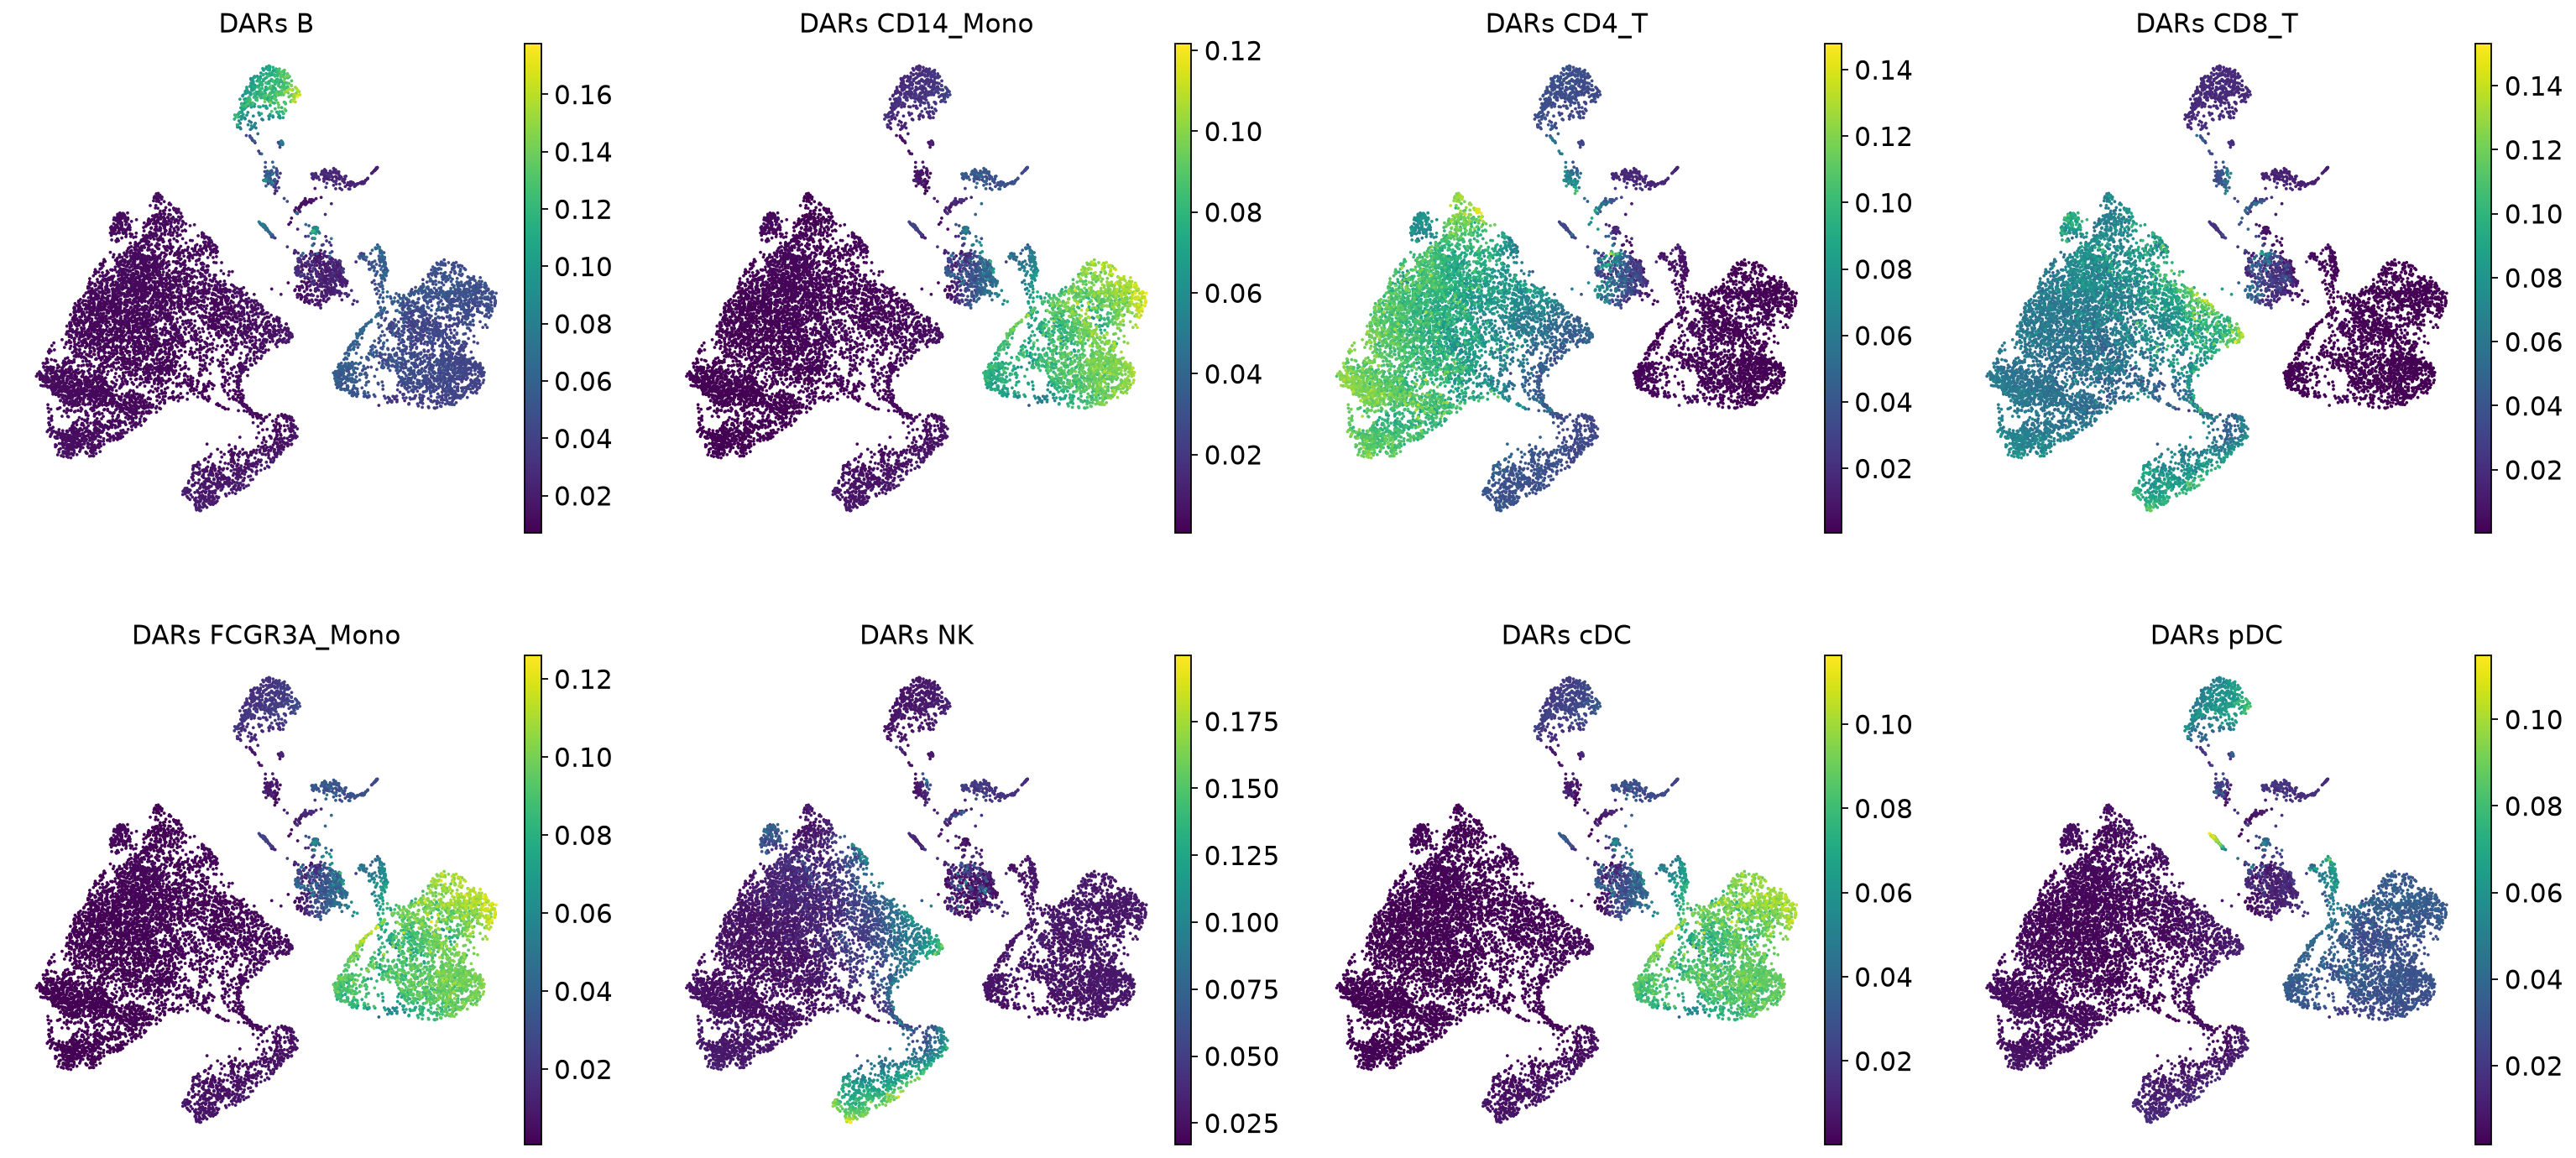

In [30]:
signatures = ad.read_h5ad("signatures.h5ad")
auc = pd.DataFrame(signatures.obsm["AUCell"], index=signatures.obs_names, columns=signature_names)
adata.obs[[f"DARs {name}" for name in signature_names]] = auc.to_numpy()
sc.pl.umap(adata, color=[f"DARs {name}" for name in signature_names], cmap="viridis", ncols=4)

## Gene activity

Gene activity is estimated from the imputed accessibility of the regions around each
gene (weighted by distance). It is stored as an AnnData file (cells x genes), which can
be used like gene expression data, e.g. to look at marker genes or to integrate with
scRNA-seq data.

In [31]:
!pycistopic gene_activity -a pbmc_10k.h5ad -t ref/hg38.tss.bed -c ref/hg38.chrom.sizes -o gene_activity.h5ad
gene_activity = ad.read_h5ad("gene_activity.h5ad")
gene_activity.obs["cell_type"] = adata.obs["cell_type"]
gene_activity.obsm["X_umap"] = adata.obsm["X_umap"]
sc.pp.normalize_total(gene_activity, target_sum=1e4)
sc.pp.log1p(gene_activity)
gene_activity

Writing gene activity (10350 cells x 18163 genes) to "gene_activity.h5ad".


AnnData object with n_obs × n_vars = 10350 × 18163
    obs: 'barcode_rank', 'total_fragments_count', 'log10_total_fragments_count', 'unique_fragments_count', 'log10_unique_fragments_count', 'total_fragments_in_peaks_count', 'log10_total_fragments_in_peaks_count', 'unique_fragments_in_peaks_count', 'log10_unique_fragments_in_peaks_count', 'fraction_of_fragments_in_peaks', 'duplication_count', 'duplication_ratio', 'nucleosome_signal', 'tss_enrichment', 'pdf_values_for_tss_enrichment', 'pdf_values_for_fraction_of_fragments_in_peaks', 'pdf_values_for_duplication_ratio', 'sample_id', 'cell_type', 'leiden_atac'
    uns: 'pycistopic', 'log1p'
    obsm: 'X_topic', 'X_umap'
    layers: None (.X)

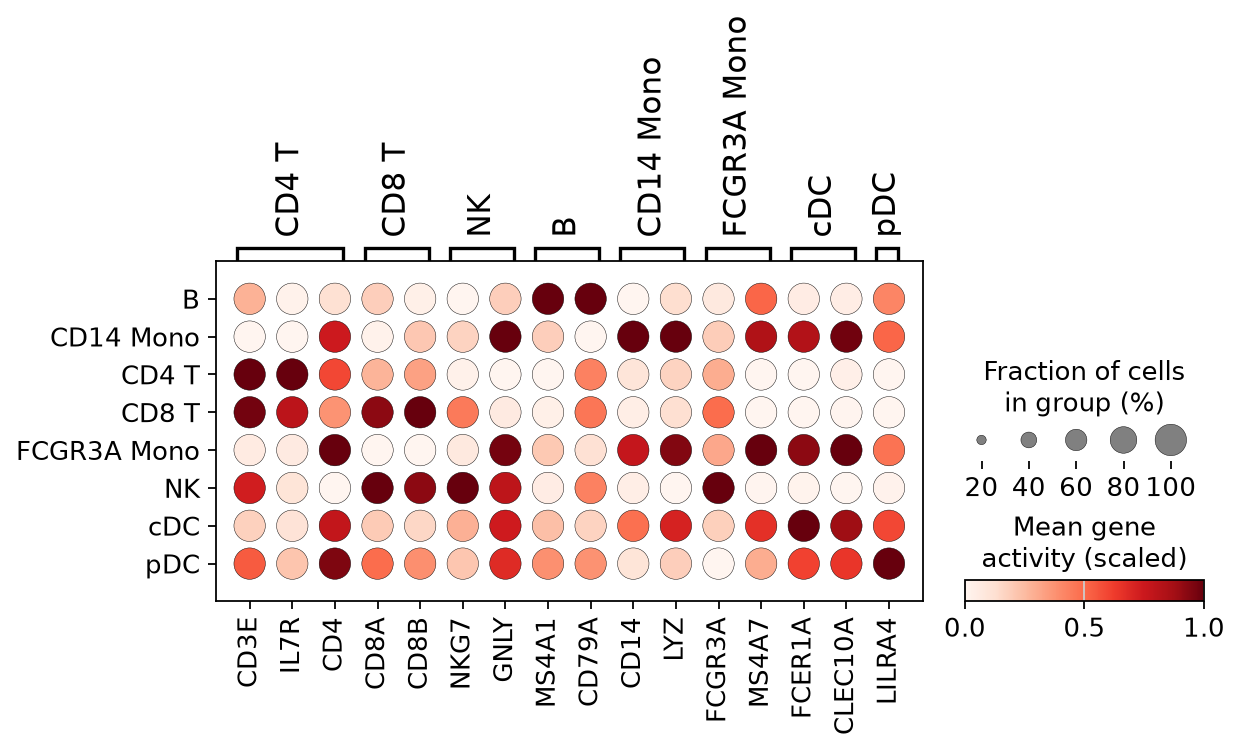

In [32]:
cell_type_names = adata.obs["cell_type"].cat.categories.to_list()
marker_genes = {ct: [g for g in genes if g in gene_activity.var_names] for ct, genes in markers.items() if ct in cell_type_names}
sc.pl.dotplot(
    gene_activity[gene_activity.obs["cell_type"].notna()],
    marker_genes,
    groupby="cell_type",
    standard_scale="var",
    colorbar_title="Mean gene\nactivity (scaled)",
)

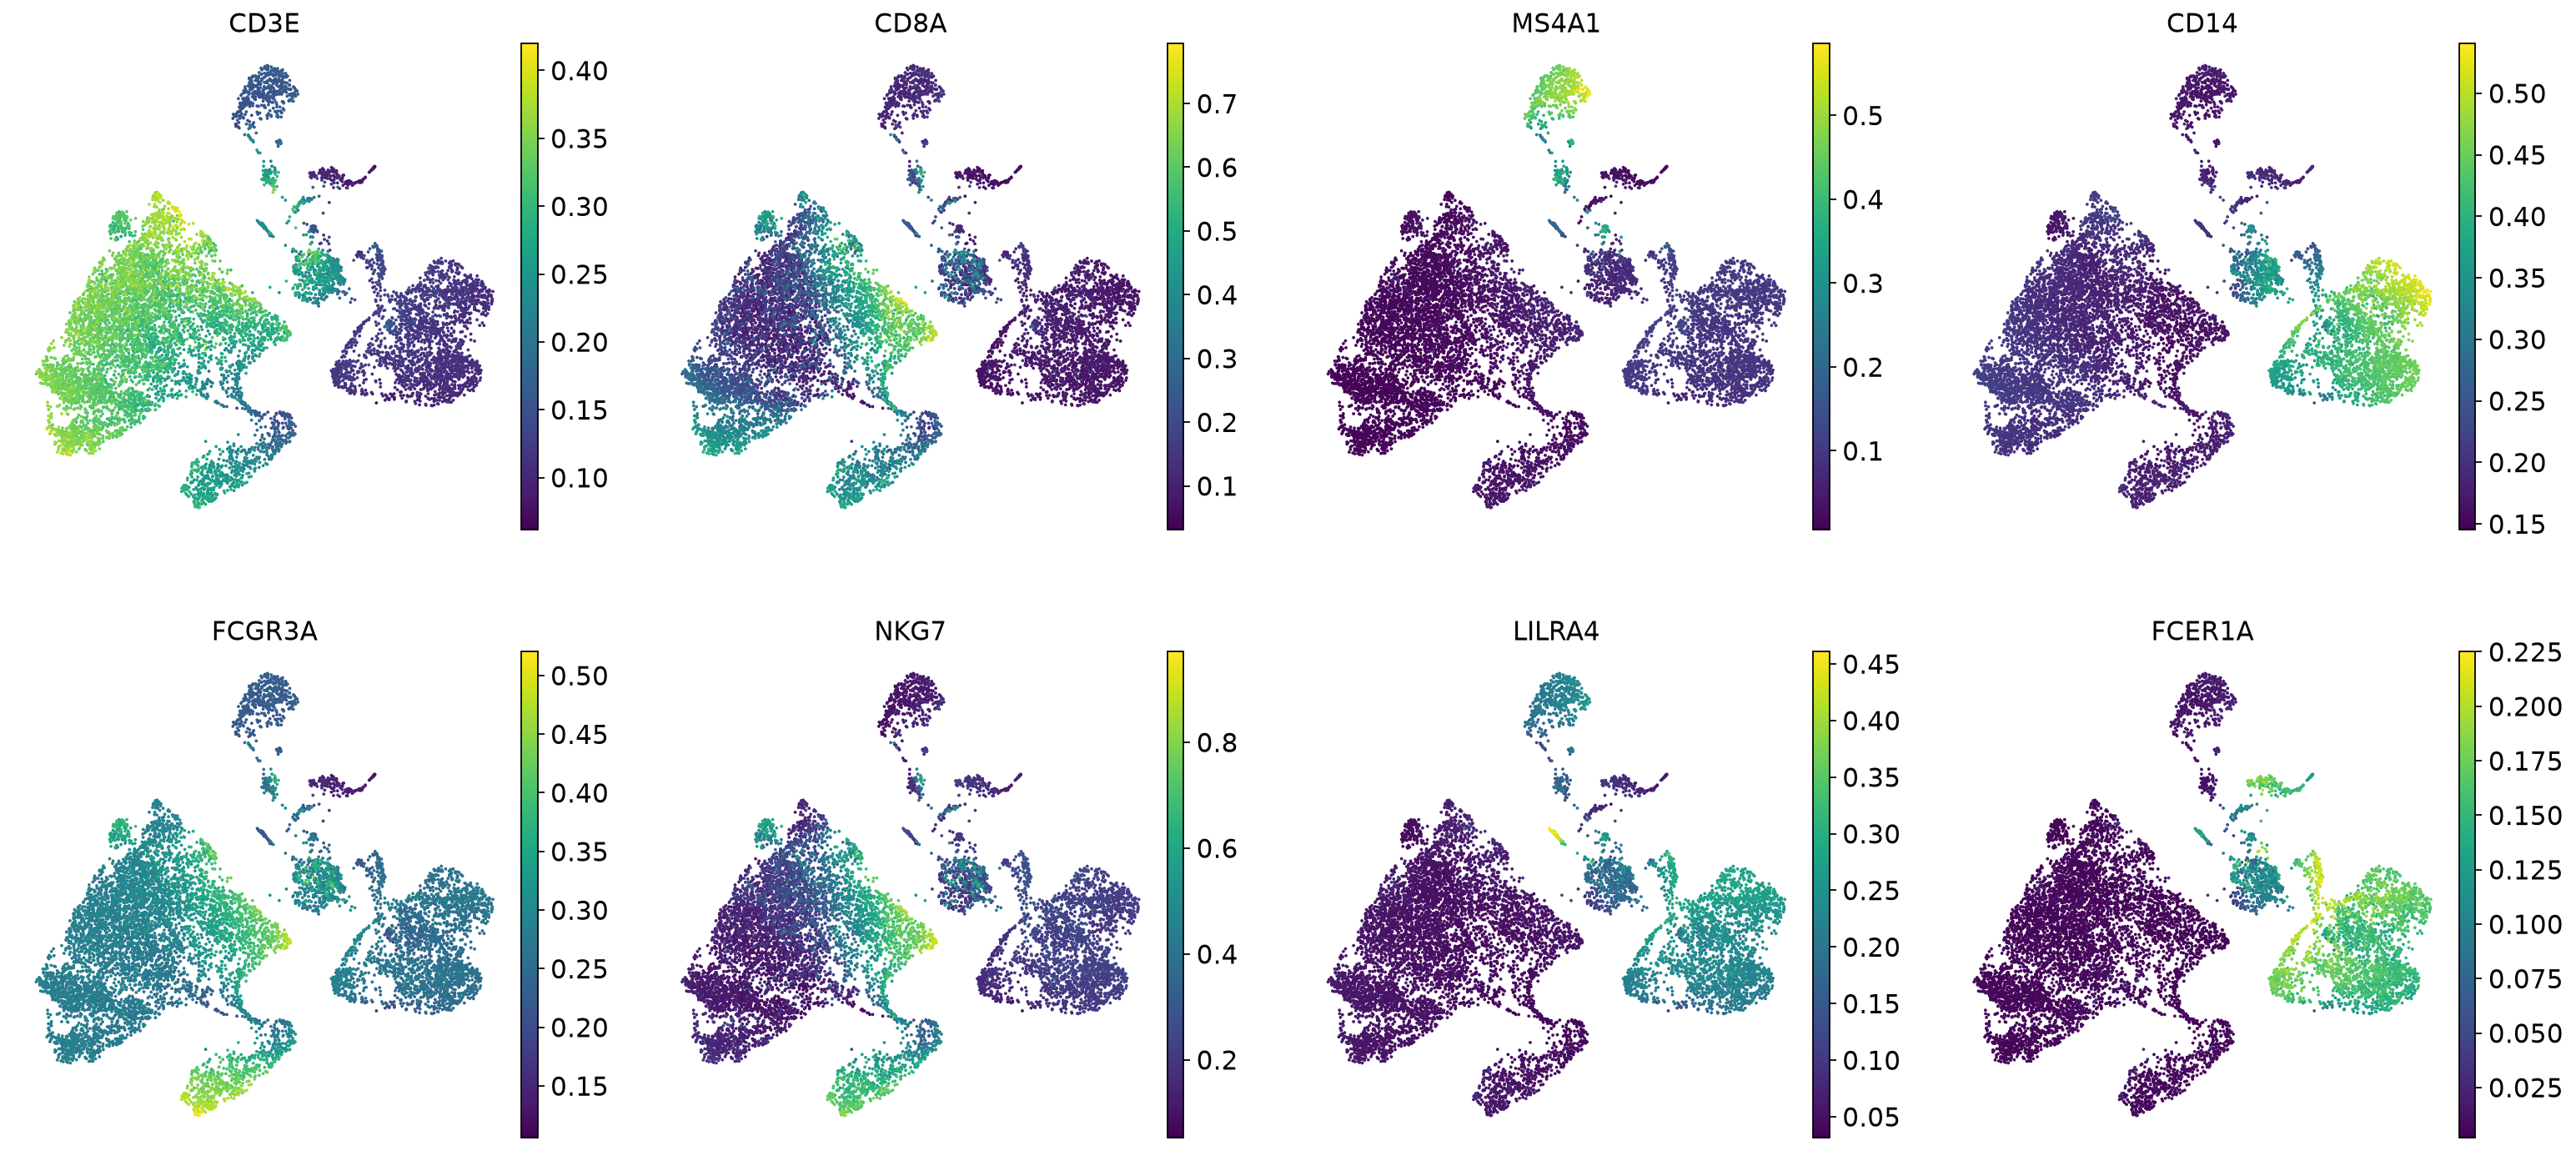

In [33]:
sc.pl.umap(gene_activity, color=["CD3E", "CD8A", "MS4A1", "CD14", "FCGR3A", "NKG7", "LILRA4", "FCER1A"], cmap="viridis", ncols=4)

## Next steps

* [SCENIC+](https://scenicplus.readthedocs.io/) uses the topics and DARs to find
  enhancer-driven gene regulatory networks.
* Batch effects between samples can be corrected with Harmony on `X_topic` (see the
  [FAQ](../faqs.rst)).